In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
print("ML ENVIRONMENT READY")

ML ENVIRONMENT READY


In [3]:
from sklearn.datasets import load_diabetes 
dataset = load_diabetes(as_frame=True)
df=dataset.frame
print(df.shape)
df.head()
X = df.drop(columns=["target"])
y = df["target"]
print("X shape:",X.shape)
print("y shape:",y.shape)
print(X.head())

(442, 11)
X shape: (442, 10)
y shape: (442,)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)

(353, 10)
(89, 10)


In [13]:
from sklearn.linear_model import LinearRegression
X1 = X[["bmi"]] 
Xtr,Xte,ytr,yte = train_test_split(X1, y, test_size=0.2, random_state=42)
simple = LinearRegression() 
simple.fit(Xtr, ytr)
pred = simple.predict(Xte) 
print("slope:", simple.coef_[0]) 
print("Intercept:", simple.intercept_) 
print("First 5 prediction:", pred[:5])

slope: 998.577689137559
Intercept: 152.00335421448167
First 5 prediction: [145.80622687 188.85739048 147.95878505 203.92529774 131.8145987 ]


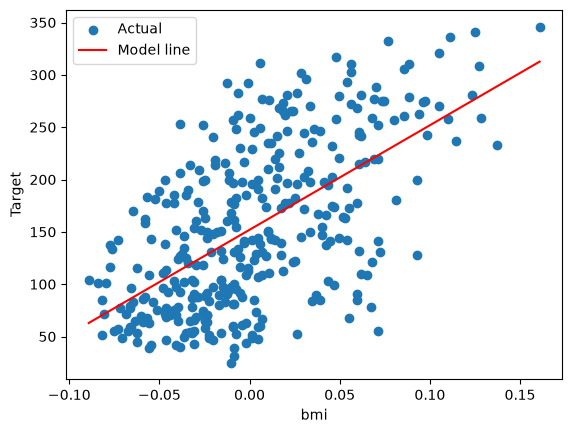

In [22]:
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["bmi"].values)
plt.scatter(Xtr["bmi"],ytr,label="Actual")
plt.plot(Xtr["bmi"].values[order],pred_train[order],
color="red",label="Model line")
plt.xlabel("bmi")
plt.ylabel("Target")
plt.legend()
plt.show()



In [24]:
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficient:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First presictions:", pred_multi[:5])

Coefficient: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First presictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]


In [25]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
poly = make_pipeline(
PolynomialFeatures(degree=2, include_bias=False),
LinearRegression()
)
poly.fit(X_train[["bmi"]], y_train)
poly_pred = poly.predict(X_test[["bmi"]])
print(poly_pred[:5])

[144.31652431 187.37853935 146.40224431 203.1205058  130.93222915]


In [26]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, pred_multi)
print("MSE:", mse)

MSE: 2900.1936284934827
